# Treinamento do modelo

Notebook da Fase 1: treina, avalia e salva o modelo que a API usa.

O modelo vem do meu mini-projeto `multiclass-predictive-pipeline` (Módulo 2, Semana 6), onde comparei KNN, Random Forest e uma rede neural MLP no MNIST. A MLP ganhou, com 97,36% de acurácia no teste.

Aqui mantive a mesma base, a mesma divisão dos dados e a mesma arquitetura da rede. O que mudou para colocar em produção:

- a rede passou do Keras para o `MLPClassifier` do scikit-learn, junto com o `MinMaxScaler` num único `Pipeline`. Assim a API carrega um arquivo só e não precisa do TensorFlow;
- usei early stopping no lugar de um número fixo de épocas;
- incluí tamanho do arquivo e tempo de resposta na escolha do modelo;
- adicionei um limiar de confiança, por causa da "falsa certeza" que apareceu no Desafio B;
- o pré-processamento das minhas imagens agora inverte as cores sozinho e centraliza pelo centro de massa.

Rode o notebook a partir da raiz do repositório.

## Importações

In [1]:
import io
import json
import os
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

from app.ml.preprocessing import N_PIXELS, preparar_arquivo

RANDOM_STATE = 42
PASTA_DADOS = Path("data")
PASTA_IMAGENS_PROPRIAS = PASTA_DADOS / "imagens_proprias"
PASTA_MODELOS = Path("models")
CAMINHO_MODELO = PASTA_MODELOS / "digit_mlp_pipeline.joblib"
CAMINHO_METRICAS = PASTA_MODELOS / "metrics.json"
VERSAO_MODELO = "1.0.0"

sns.set_theme(style="whitegrid")
print(f"scikit-learn {sklearn.__version__} | numpy {np.__version__} | Python {platform.python_version()}")

scikit-learn 1.9.1 | numpy 2.5.3 | Python 3.13.18


## 1. Carregamento da base

Igual ao projeto anterior: baixa o MNIST do OpenML na primeira vez e salva um cache em `data/` (fora do Git, por ser grande).

In [2]:
PASTA_DADOS.mkdir(exist_ok=True)
caminho_X = PASTA_DADOS / "mnist_X.npy"
caminho_y = PASTA_DADOS / "mnist_y.npy"

if caminho_X.exists() and caminho_y.exists():
    print("Carregando MNIST do cache local...")
    X = np.load(caminho_X)
    y = np.load(caminho_y)
else:
    print("Baixando o dataset MNIST do OpenML...")
    mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
    X = mnist.data
    y = mnist.target.astype(int)
    print("Salvando cache local em data/...")
    np.save(caminho_X, X)
    np.save(caminho_y, y)

X = X.astype(np.uint8)  # pixels são inteiros de 0 a 255 (reduz a memória em 8×)
y = y.astype(np.int64)
print(f"X: {X.shape} ({X.dtype}) | y: {y.shape} ({y.dtype})")

Carregando MNIST do cache local...


X: (70000, 784) (uint8) | y: (70000,) (int64)


## 2. Olhada rápida nos dados

In [3]:
print(f"Amostras: {X.shape[0]} | Atributos (pixels): {X.shape[1]} = 28 × 28")
print(f"Valores ausentes em X: {np.isnan(X.astype(float)).sum()} | em y: {pd.isna(y).sum()}")
print(f"Faixa dos pixels: {X.min()} a {X.max()}")
print(f"Classes: {np.unique(y)}")

Amostras: 70000 | Atributos (pixels): 784 = 28 × 28
Valores ausentes em X: 0 | em y: 0


Faixa dos pixels: 0 a 255
Classes: [0 1 2 3 4 5 6 7 8 9]


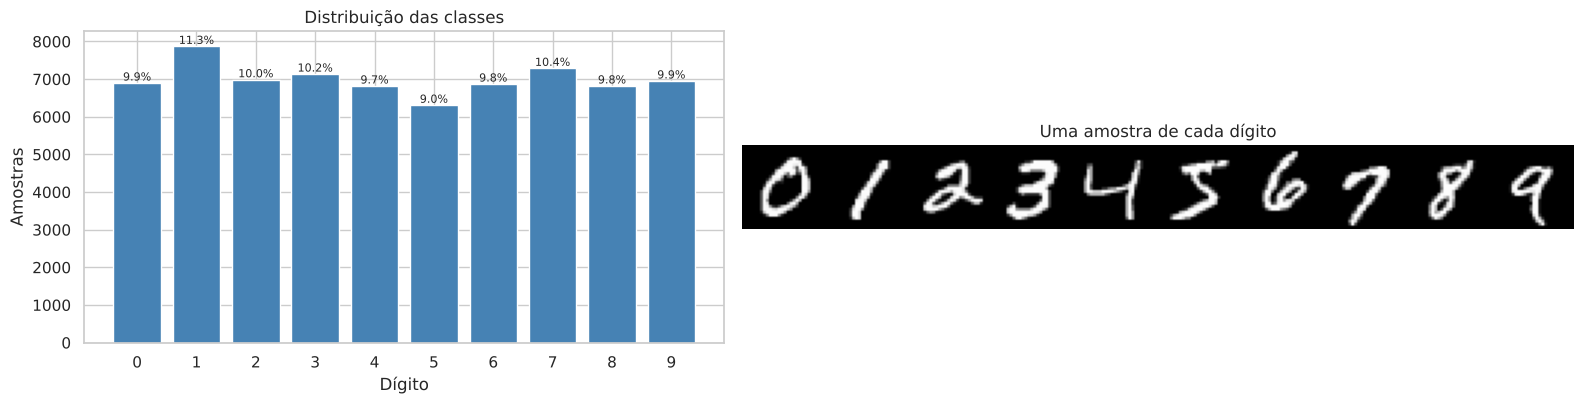

In [4]:
valores, contagens = np.unique(y, return_counts=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].bar(valores, contagens, color="steelblue")
for v, c in zip(valores, contagens):
    axes[0].text(v, c + 60, f"{c / len(y):.1%}", ha="center", fontsize=8)
axes[0].set_xticks(valores)
axes[0].set_xlabel("Dígito")
axes[0].set_ylabel("Amostras")
axes[0].set_title("Distribuição das classes")

grade = np.hstack([X[np.where(y == d)[0][0]].reshape(28, 28) for d in range(10)])
axes[1].imshow(grade, cmap="gray")
axes[1].set_title("Uma amostra de cada dígito")
axes[1].axis("off")
plt.tight_layout()
plt.show()

Não há valores ausentes nem colunas categóricas, então não precisei de imputação nem de one-hot encoding. O alvo já é um número de 0 a 9.

Os pixels vão de 0 a 255, por isso uso o `MinMaxScaler` para levar tudo para 0 a 1, o que ajuda a rede a treinar. As classes estão equilibradas, então a acurácia é uma boa métrica.

## 3. Divisão dos dados

Mesma divisão do projeto anterior: 70% treino, 10% validação e 20% teste, estratificada. O scaler fica dentro do pipeline, então só aprende com o treino.

In [5]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, stratify=y_temp,
                                                  random_state=RANDOM_STATE)  # 0,125 × 80% = 10%

print(f"Treino:    {len(X_train)} amostras")
print(f"Validação: {len(X_val)} amostras")
print(f"Teste:     {len(X_test)} amostras")


def criar_pipeline(modelo) -> Pipeline:
    return Pipeline([("escala", MinMaxScaler()), ("modelo", modelo)])

Treino:    49000 amostras
Validação: 7000 amostras
Teste:     14000 amostras


## 4. Qual modelo levar para a API

Retreinei as melhores versões dos três modelos e comparei na validação. Além da acurácia, medi o tamanho do arquivo salvo e o tempo de uma previsão, que importam numa API.

In [6]:
def tamanho_artefato_mb(objeto) -> float:
    buffer = io.BytesIO()
    joblib.dump(objeto, buffer, compress=3)
    return buffer.tell() / 1024 ** 2


def latencia_ms(pipeline, amostras, repeticoes=200) -> float:
    inicio = time.perf_counter()
    for i in range(repeticoes):
        pipeline.predict(amostras[i % len(amostras)].reshape(1, -1))
    return (time.perf_counter() - inicio) / repeticoes * 1000


candidatos = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3, weights="distance", n_jobs=-1),
    "Random Forest (100, depth 20)": RandomForestClassifier(n_estimators=100, max_depth=20,
                                                            random_state=RANDOM_STATE, n_jobs=-1),
    "MLP (128 → 64)": MLPClassifier(hidden_layer_sizes=(128, 64), learning_rate_init=0.001, batch_size=32,
                                    max_iter=50, early_stopping=True, n_iter_no_change=5,
                                    random_state=RANDOM_STATE),
}

linhas = []
for nome, modelo in candidatos.items():
    pipe = criar_pipeline(modelo)
    inicio = time.perf_counter()
    pipe.fit(X_train, y_train)
    tempo_treino = time.perf_counter() - inicio
    linhas.append({"modelo": nome, "acuracia_val": accuracy_score(y_val, pipe.predict(X_val)),
                   "treino_s": tempo_treino, "artefato_mb": tamanho_artefato_mb(pipe),
                   "latencia_ms": latencia_ms(pipe, X_val)})
    if nome.startswith("MLP"):
        mlp_padrao = pipe

comparacao = pd.DataFrame(linhas).set_index("modelo")
comparacao.style.format({"acuracia_val": "{:.4f}", "treino_s": "{:.1f}", "artefato_mb": "{:.1f}",
                         "latencia_ms": "{:.2f}"})

,acuracia_val,treino_s,artefato_mb,latencia_ms
modelo,,,,
KNN (k=3),0.9723,0.4,15.8,22.62
"Random Forest (100, depth 20)",0.9651,11.9,17.7,23.28
MLP (128 → 64),0.9760,90.9,2.3,0.35


O KNN e a Random Forest deram as mesmas acurácias do projeto anterior, o que confirma que os dados e a divisão são os mesmos.

A MLP ganhou em tudo: maior acurácia (0,976), arquivo de 2,3 MB (contra 16 a 18 MB dos outros) e previsão em menos de 1 ms (contra ~22 ms). O KNN precisa guardar todas as imagens de treino e comparar cada nova imagem com elas, o que pesa num servidor. Por isso segui com a MLP.

## 5. Ajuste da rede

Testei as mesmas três configurações do projeto anterior, agora com early stopping: o treino para quando a validação interna não melhora por 5 épocas.

In [7]:
configuracoes = [
    {"hidden_layer_sizes": (64, 32), "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (128, 64), "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (128, 64), "learning_rate_init": 0.01},
]

resultados_mlp = []
pipelines_mlp = {}
for config in configuracoes:
    rotulo = f"{config['hidden_layer_sizes']}, lr={config['learning_rate_init']}"
    if config == {"hidden_layer_sizes": (128, 64), "learning_rate_init": 0.001}:
        pipe = mlp_padrao  # já treinado na seção 4, com a mesma configuração
    else:
        pipe = criar_pipeline(MLPClassifier(**config, batch_size=32, max_iter=50, early_stopping=True,
                                            n_iter_no_change=5, random_state=RANDOM_STATE)).fit(X_train, y_train)
    rede = pipe.named_steps["modelo"]
    pipelines_mlp[rotulo] = pipe
    resultados_mlp.append({"configuracao": rotulo, "epocas": rede.n_iter_,
                           "acuracia_treino": accuracy_score(y_train, pipe.predict(X_train)),
                           "acuracia_val": accuracy_score(y_val, pipe.predict(X_val))})

tabela_mlp = pd.DataFrame(resultados_mlp)
tabela_mlp["gap"] = tabela_mlp["acuracia_treino"] - tabela_mlp["acuracia_val"]
melhor_config = tabela_mlp.loc[tabela_mlp["acuracia_val"].idxmax(), "configuracao"]
modelo_final = pipelines_mlp[melhor_config]
print(f"Melhor configuração na validação: {melhor_config}")
tabela_mlp.style.format({"acuracia_treino": "{:.4f}", "acuracia_val": "{:.4f}", "gap": "{:.4f}"})

Melhor configuração na validação: (128, 64), lr=0.001


,configuracao,epocas,acuracia_treino,acuracia_val,gap
0,"(64, 32), lr=0.001",17,0.9929,0.9734,0.0195
1,"(128, 64), lr=0.001",24,0.9963,0.9760,0.0203
2,"(128, 64), lr=0.01",26,0.9828,0.9639,0.0189


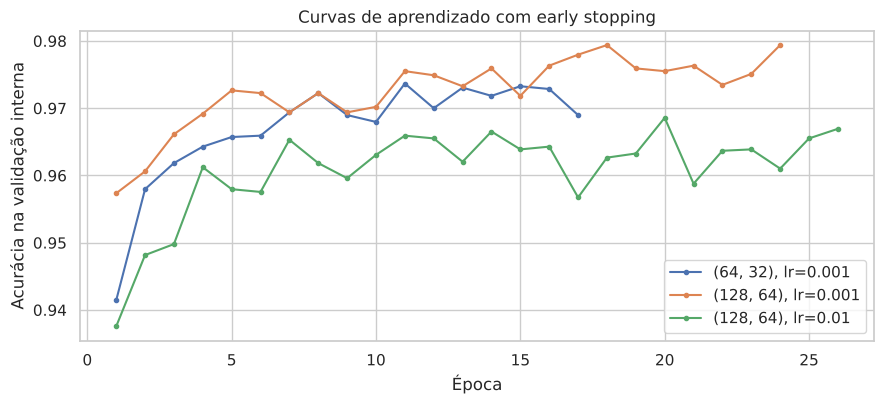

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for rotulo, pipe in pipelines_mlp.items():
    ax.plot(np.arange(1, len(pipe.named_steps["modelo"].validation_scores_) + 1),
            pipe.named_steps["modelo"].validation_scores_, marker="o", markersize=3, label=rotulo)
ax.set_xlabel("Época")
ax.set_ylabel("Acurácia na validação interna")
ax.set_title("Curvas de aprendizado com early stopping")
ax.legend()
plt.tight_layout()
plt.show()

A configuração (128, 64) com taxa 0,001 foi a melhor, como no projeto anterior. Com taxa 0,01 a acurácia caiu, porque os passos ficam grandes demais. A diferença entre treino e validação é pequena nas três, então não vi overfitting relevante.

## 6. Métricas no teste

Avaliação final, feita uma única vez no conjunto de teste. Como são 10 classes, uso médias macro para precisão, recall e F1, e o ROC-AUC no modo one-vs-rest.

In [9]:
proba_test = modelo_final.predict_proba(X_test)
pred_test = proba_test.argmax(axis=1)

metricas_teste = {
    "acuracia": accuracy_score(y_test, pred_test),
    "precisao_macro": precision_score(y_test, pred_test, average="macro"),
    "recall_macro": recall_score(y_test, pred_test, average="macro"),
    "f1_macro": f1_score(y_test, pred_test, average="macro"),
    "f1_ponderado": f1_score(y_test, pred_test, average="weighted"),
    "roc_auc_ovr": roc_auc_score(y_test, proba_test, multi_class="ovr", average="macro"),
}
pd.Series(metricas_teste, name="teste").to_frame().style.format("{:.4f}")

,teste
acuracia,0.9775
precisao_macro,0.9774
recall_macro,0.9772
f1_macro,0.9773
f1_ponderado,0.9775
roc_auc_ovr,0.9994


In [10]:
print(classification_report(y_test, pred_test, digits=4))

              precision    recall  f1-score   support

           0     0.9738    0.9942    0.9839      1381
           1     0.9830    0.9937    0.9883      1575
           2     0.9848    0.9764    0.9806      1398
           3     0.9823    0.9727    0.9775      1428
           4     0.9756    0.9685    0.9721      1365
           5     0.9737    0.9683    0.9710      1263
           6     0.9919    0.9760    0.9839      1375
           7     0.9834    0.9774    0.9804      1459
           8     0.9742    0.9700    0.9721      1365
           9     0.9516    0.9748    0.9631      1391

    accuracy                         0.9775     14000
   macro avg     0.9774    0.9772    0.9773     14000
weighted avg     0.9776    0.9775    0.9775     14000



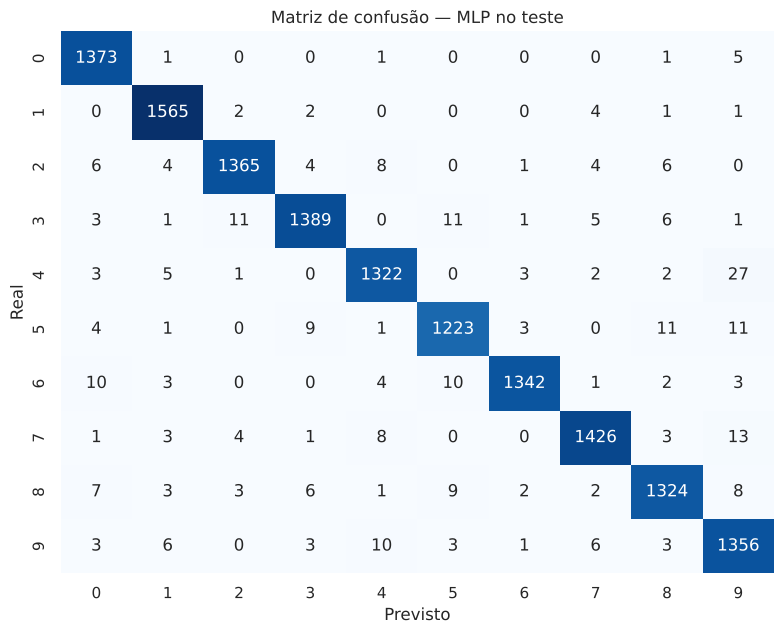

Erro mais frequente: dígito 4 classificado como 9 (27 vezes)


In [11]:
matriz = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusão — MLP no teste")
plt.tight_layout()
plt.show()

erros = matriz.copy()
np.fill_diagonal(erros, 0)
real, previsto = np.unravel_index(erros.argmax(), erros.shape)
print(f"Erro mais frequente: dígito {real} classificado como {previsto} ({erros[real, previsto]} vezes)")

Acurácia de 97,75% no teste, acima dos 97,36% do projeto anterior. Precisão, recall e F1 ficaram praticamente iguais à acurácia, então nenhum dígito ficou muito pior que os outros. ROC-AUC de 0,9994.

O erro mais comum continua sendo o 4 confundido com 9.

## 7. Limiar de confiança

No Desafio B, o modelo errava com muita certeza. Para ter pelo menos um sinal de dúvida, uso a probabilidade da classe prevista: abaixo de um limiar, a API avisa que a previsão não é confiável.

Escolhi na validação o menor limiar em que as previsões aceitas acertam pelo menos 98,5%.

In [12]:
proba_val = modelo_final.predict_proba(X_val)
confianca_val = proba_val.max(axis=1)
acerto_val = proba_val.argmax(axis=1) == y_val

linhas = []
for limiar in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99]:
    aceitas = confianca_val >= limiar
    linhas.append({"limiar": limiar, "cobertura": aceitas.mean(),
                   "acuracia_aceitas": acerto_val[aceitas].mean(),
                   "acuracia_sinalizadas": acerto_val[~aceitas].mean() if (~aceitas).any() else np.nan,
                   "sinalizadas": int((~aceitas).sum())})
tabela_limiar = pd.DataFrame(linhas)
LIMIAR_CONFIANCA = float(tabela_limiar.loc[tabela_limiar["acuracia_aceitas"] >= 0.985, "limiar"].min())
print(f"Limiar de confiança escolhido: {LIMIAR_CONFIANCA}")
tabela_limiar.style.format({"cobertura": "{:.2%}", "acuracia_aceitas": "{:.4f}", "acuracia_sinalizadas": "{:.4f}"})

Limiar de confiança escolhido: 0.9


,limiar,cobertura,acuracia_aceitas,acuracia_sinalizadas,sinalizadas
0,0.500000,99.89%,0.9768,0.2500,8
1,0.600000,99.61%,0.9783,0.3704,27
2,0.700000,99.09%,0.9805,0.4844,64
3,0.800000,98.54%,0.9830,0.5000,102
4,0.850000,98.23%,0.9840,0.5323,124
5,0.900000,97.64%,0.9860,0.5636,165
6,0.950000,96.84%,0.9885,0.5928,221
7,0.990000,94.69%,0.9919,0.6935,372


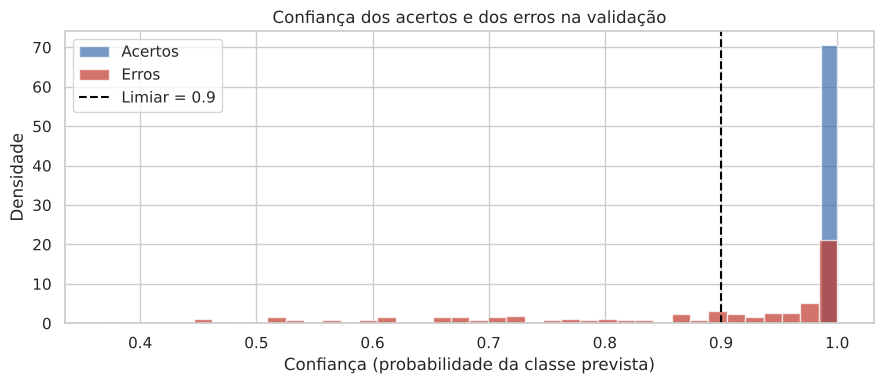

No teste: 97.78% das previsões são confiáveis, com acurácia de 0.9874; as 311 sinalizadas têm acurácia de 0.5434


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(confianca_val[acerto_val], bins=40, alpha=0.7, label="Acertos", color="#3b6ea8", density=True)
ax.hist(confianca_val[~acerto_val], bins=40, alpha=0.7, label="Erros", color="#c0392b", density=True)
ax.axvline(LIMIAR_CONFIANCA, color="black", linestyle="--", label=f"Limiar = {LIMIAR_CONFIANCA}")
ax.set_xlabel("Confiança (probabilidade da classe prevista)")
ax.set_ylabel("Densidade")
ax.set_title("Confiança dos acertos e dos erros na validação")
ax.legend()
plt.tight_layout()
plt.show()

aceitas_teste = proba_test.max(axis=1) >= LIMIAR_CONFIANCA
print(f"No teste: {aceitas_teste.mean():.2%} das previsões são confiáveis, com acurácia de "
      f"{(pred_test[aceitas_teste] == y_test[aceitas_teste]).mean():.4f}; "
      f"as {(~aceitas_teste).sum()} sinalizadas têm acurácia de {(pred_test[~aceitas_teste] == y_test[~aceitas_teste]).mean():.4f}")

Com limiar 0,90, cerca de 98% das previsões passam, com 98,7% de acerto no teste. As que ficam abaixo acertam só ~54%, então faz sentido sinalizá-las.

O histograma mostra que alguns erros ainda acontecem com confiança altíssima. O limiar ajuda, mas não resolve a falsa certeza.

## 8. Teste com as minhas imagens

Os 10 dígitos que desenhei no Paint passam pela função `preparar_arquivo` (`app/ml/preprocessing.py`), a mesma que a API usa no upload de imagens.

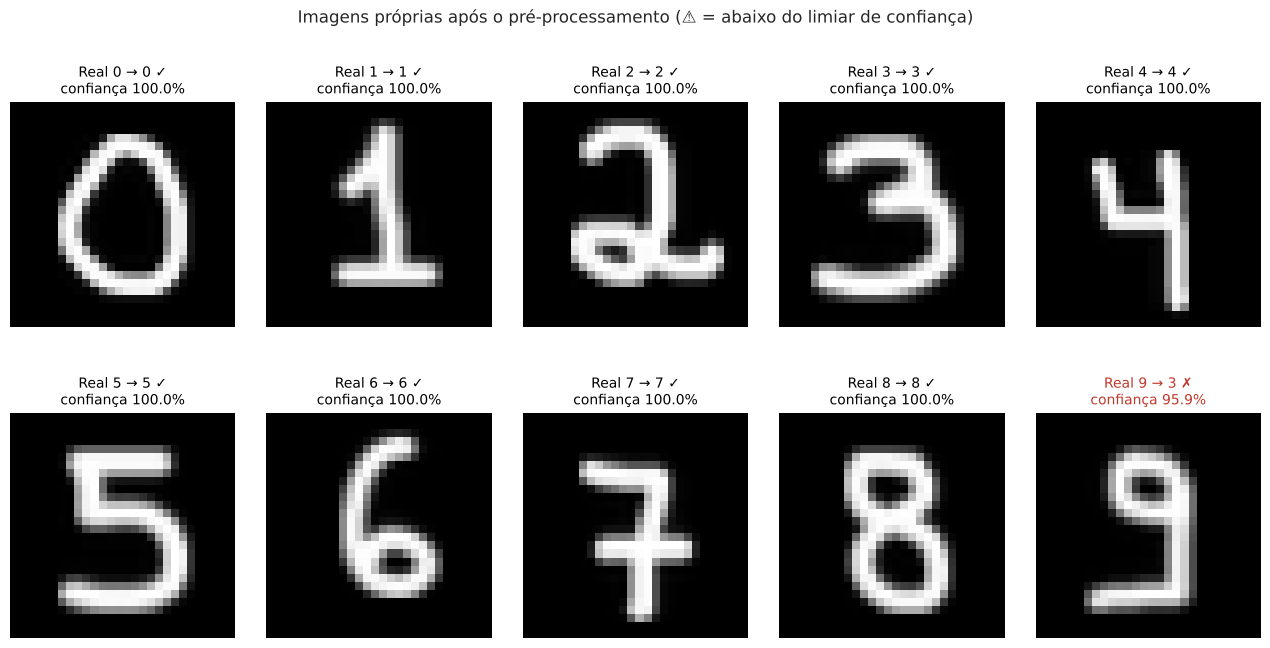

Acertos: 9 de 10


,arquivo,real,previsto,confianca,confiavel,acertou
0,digito_0.png,0,0,100.00%,True,True
1,digito_1.png,1,1,100.00%,True,True
2,digito_2.png,2,2,100.00%,True,True
3,digito_3.png,3,3,100.00%,True,True
4,digito_4.png,4,4,100.00%,True,True
5,digito_5.png,5,5,100.00%,True,True
6,digito_6.png,6,6,99.98%,True,True
7,digito_7.png,7,7,100.00%,True,True
8,digito_8.png,8,8,100.00%,True,True
9,digito_9.png,9,3,95.93%,True,False


In [14]:
arquivos = sorted(PASTA_IMAGENS_PROPRIAS.glob("digito_*.png"))
resultados_proprios = []
for caminho in arquivos:
    pixels = preparar_arquivo(caminho)
    probabilidades = modelo_final.predict_proba(pixels.reshape(1, -1).astype(np.float64))[0]
    real = int(caminho.stem.split("_")[1])
    previsto = int(probabilidades.argmax())
    resultados_proprios.append({"arquivo": caminho.name, "real": real, "previsto": previsto,
                                "confianca": probabilidades.max(),
                                "confiavel": probabilidades.max() >= LIMIAR_CONFIANCA,
                                "acertou": real == previsto, "pixels": pixels})

fig, axes = plt.subplots(2, 5, figsize=(13, 6.6))
for ax, r in zip(axes.ravel(), resultados_proprios):
    ax.imshow(r["pixels"].reshape(28, 28), cmap="gray")
    simbolo = "✓" if r["acertou"] else "✗"
    alerta = "" if r["confiavel"] else " ⚠"
    ax.set_title(f"Real {r['real']} → {r['previsto']} {simbolo}\nconfiança {r['confianca']:.1%}{alerta}",
                 color="black" if r["acertou"] else "#c0392b", fontsize=10)
    ax.axis("off")
plt.suptitle("Imagens próprias após o pré-processamento (⚠ = abaixo do limiar de confiança)", fontsize=12)
plt.tight_layout()
plt.subplots_adjust(top=0.84, hspace=0.38)
plt.show()

tabela_proprias = pd.DataFrame(resultados_proprios).drop(columns="pixels")
print(f"Acertos: {tabela_proprias['acertou'].sum()} de {len(tabela_proprias)}")
tabela_proprias.style.format({"confianca": "{:.2%}"})

9 de 10 acertos, igual ao projeto anterior. O 9 continua sendo lido como 3, e com 95,9% de confiança, acima do limiar. É mais um caso de falsa certeza: o traço feito com mouse é diferente do MNIST, que foi escrito com caneta.

## 9. Salvando o modelo

Salvo em `models/` o pipeline, o limiar de confiança e alguns metadados num único `.joblib`. As métricas também vão para `metrics.json`, que a API mostra em `/v1/model/info`.

In [15]:
PASTA_MODELOS.mkdir(exist_ok=True)
rede = modelo_final.named_steps["modelo"]

metadados = {
    "nome": "digit-mlp-classifier",
    "versao": VERSAO_MODELO,
    "algoritmo": "MLPClassifier",
    "arquitetura": f"784 → {' → '.join(str(n) for n in rede.hidden_layer_sizes)} → 10 (ReLU, softmax)",
    "hiperparametros": {"hidden_layer_sizes": list(rede.hidden_layer_sizes),
                        "learning_rate_init": rede.learning_rate_init, "batch_size": rede.batch_size,
                        "early_stopping": True, "epocas_treinadas": int(rede.n_iter_)},
    "limiar_confianca": LIMIAR_CONFIANCA,
    "treinado_em": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "scikit_learn": sklearn.__version__,
    "base_de_dados": "MNIST (OpenML mnist_784)",
    "amostras": {"treino": len(X_train), "validacao": len(X_val), "teste": len(X_test)},
    "metricas_teste": {k: round(float(v), 4) for k, v in metricas_teste.items()},
    "imagens_proprias": {"acertos": int(tabela_proprias["acertou"].sum()), "total": len(tabela_proprias)},
}

artefato = {"pipeline": modelo_final, "limiar_confianca": LIMIAR_CONFIANCA, "metadados": metadados}
joblib.dump(artefato, CAMINHO_MODELO, compress=3)
CAMINHO_METRICAS.write_text(json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Modelo salvo em   : {CAMINHO_MODELO} ({CAMINHO_MODELO.stat().st_size / 1024:.0f} KB)")
print(f"Métricas salvas em: {CAMINHO_METRICAS}")
print(json.dumps(metadados["metricas_teste"], indent=2))

Modelo salvo em   : models/digit_mlp_pipeline.joblib (2377 KB)
Métricas salvas em: models/metrics.json
{
  "acuracia": 0.9775,
  "precisao_macro": 0.9774,
  "recall_macro": 0.9772,
  "f1_macro": 0.9773,
  "f1_ponderado": 0.9775,
  "roc_auc_ovr": 0.9994
}


## 10. Conferindo o arquivo salvo

Carrego o arquivo como a API faz e verifico se as previsões são as mesmas.

In [16]:
carregado = joblib.load(CAMINHO_MODELO)
pipeline_carregado = carregado["pipeline"]

identico = np.allclose(pipeline_carregado.predict_proba(X_test), proba_test)
print(f"Probabilidades idênticas após desserializar: {identico}")

pixels_7 = preparar_arquivo(PASTA_IMAGENS_PROPRIAS / "digito_7.png").reshape(1, -1).astype(np.float64)
proba_7 = pipeline_carregado.predict_proba(pixels_7)[0]
print(f"digito_7.png → previsto {proba_7.argmax()} com confiança {proba_7.max():.2%} "
      f"(limiar {carregado['limiar_confianca']})")

Probabilidades idênticas após desserializar: True
digito_7.png → previsto 7 com confiança 100.00% (limiar 0.9)


Com o modelo salvo, a API pode ser iniciada com `uvicorn app.main:app --reload`.